# Experiment 8 :: Abstractive Text Summarization with mT5 and mBART

- Language: Hindi, from the XL-Sum dataset
- 8.1 mT5 (Multilingual Text-to-Text Transfer Transformer)
- 8.2 mBART (Multilingual Bidirectional and Auto-Regressive Transformers)
- 8.3 Comparison using ROUGE-1, ROUGE-2, ROUGE-L and mBERT score (BERTScore with bert-base-multilingual-cased)

Both models are checkpoints already fine-tuned on XL-Sum, since fine-tuning mT5 or mBART-large does not fit on my laptop. They are evaluated on Hindi test articles.

In [1]:
%pip install -q torch transformers sentencepiece protobuf rouge-score bert-score pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import re
import json
import time
import tarfile
import urllib.request

import pandas as pd
import matplotlib.pyplot as plt
import torch

device = 'mps' if torch.backends.mps.is_available() else 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)

Device: mps


## Dataset (XL-Sum Hindi)

In [3]:
data_url = 'https://huggingface.co/datasets/csebuetnlp/xlsum/resolve/main/data/hindi_XLSum_v2.0.tar.bz2'
archive = 'hindi_XLSum_v2.0.tar.bz2'

if not os.path.exists('hindi_test.jsonl'):
    if not os.path.exists(archive):
        urllib.request.urlretrieve(data_url, archive)
    with tarfile.open(archive) as tar:
        member = [m for m in tar.getmembers() if m.name.endswith('test.jsonl')][0]
        member.name = 'hindi_test.jsonl'
        tar.extract(member, '.')

test_data = pd.read_json('hindi_test.jsonl', lines=True)
print('Hindi test articles:', len(test_data))
print(test_data.columns.tolist())

/var/folders/ly/l7fk5xf976qbtzsk2q5kctm80000gn/T/ipykernel_20525/807616811.py:10: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extract(member, '.')


Hindi test articles: 8847
['id', 'url', 'title', 'summary', 'text']


In [4]:
num_samples = 100
samples = test_data.sample(num_samples, random_state=42).reset_index(drop=True)

articles = [' '.join(text.split()) for text in samples['text']]
reference_summaries = [' '.join(s.split()) for s in samples['summary']]

print('Average article length (words):', int(samples['text'].str.split().str.len().mean()))
print('Average summary length (words):', int(samples['summary'].str.split().str.len().mean()))
print()
print('Title:', samples['title'][0])
print('Article:', articles[0][:400], '...')
print('Reference summary:', reference_summaries[0])

Average article length (words): 482
Average summary length (words): 27

Title: बीआर चोपड़ा की यादगार फ़िल्मों का विशेष उत्सव
Article: शुक्रवार शाम को शुरु हुए फ़ेस्टिवल में इंसाफ़ का तराज़ू फ़िल्म दिखाई गई. उत्सव के दौरान छोटी सी बात, नया दौर और वक़्त जैसी क्लासिक फ़िल्में देखने को मिलेंगी. खराब सेहत के कारण बीआर चोपड़ा ख़ुद समारोह में शामिल नहीं हो सके.फ़िल्मोत्सव का उदघाटन बीआर चोपड़ा के भाई और मशहूर फ़िल्मकार यश चोपड़ा ने किया. उन्होंने कहा, "मेरे भाई ने अपने हिसाब से फ़िल्में बनाईं- वो भी ऐसे समय में जब लोग ऐसी फ़िल्मों की व ...
Reference summary: भारतीय फ़िल्म इतिहास में फ़िल्मकार बीआर चोपड़ा का नाम बड़ा अदब से लिया जाता है. उनके 94वें जन्मदिन के मौके पर दिल्ली में बीआर चोपड़ा की फ़िल्मों का विशेष उत्सव मनाया जा रहा है.


## Summary generation

In [5]:
def generate_summaries(model, tokenizer, texts, batch_size=4, **generate_args):
    summaries = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i + batch_size]
        inputs = tokenizer(batch, return_tensors='pt', truncation=True, max_length=512, padding=True).to(device)
        with torch.no_grad():
            output_ids = model.generate(**inputs, **generate_args)
        summaries.extend(tokenizer.batch_decode(output_ids, skip_special_tokens=True))
    return summaries

## 8.1 mT5

In [6]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

mt5_name = 'csebuetnlp/mT5_multilingual_XLSum'
mt5_tokenizer = AutoTokenizer.from_pretrained(mt5_name)
mt5_model = AutoModelForSeq2SeqLM.from_pretrained(mt5_name).to(device).eval()
print('mT5 parameters:', sum(p.numel() for p in mt5_model.parameters()))

start = time.time()
mt5_summaries = generate_summaries(mt5_model, mt5_tokenizer, articles, max_length=84, num_beams=4, no_repeat_ngram_size=2)
mt5_time = time.time() - start
print(f'Time: {mt5_time:.0f}s  ({mt5_time / num_samples:.2f}s per article)')

for i in range(3):
    print()
    print('Reference:', reference_summaries[i])
    print('mT5      :', mt5_summaries[i])

W1118 22:19:55.225000 20525 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/284 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


model.safetensors: reconstructing file:   0%|          |  0.00B / 2.33GB            

model.safetensors: downloading bytes:           |  0.00B            

mT5 parameters: 582401280


Time: 616s  (6.16s per article)

Reference: भारतीय फ़िल्म इतिहास में फ़िल्मकार बीआर चोपड़ा का नाम बड़ा अदब से लिया जाता है. उनके 94वें जन्मदिन के मौके पर दिल्ली में बीआर चोपड़ा की फ़िल्मों का विशेष उत्सव मनाया जा रहा है.
mT5      : मशहूर फ़िल्मकार बीआर चोपड़ा के मुंबई में हुए फ़ेस्टिवल का उदघाटन किया गया है.

Reference: अफ़ग़ानिस्तान के कंधार में तालेबान चरमपंथियों ने जेल पर हमला करके सैकड़ों क़ैदियों को छुड़ा दिया है.
mT5      : अफ़ग़ानिस्तान की राजधानी काबुल की कंधार जेल में तालेबान के हमले में कम से कम 40 क़ैदी मारे गए हैं.

Reference: गिनीज़ वर्ल्ड रिकॉर्ड में अपना नाम दर्ज कराने की उम्मीद में एक बुल्गारियाई व्यक्ति ने बोरे में बंद होकर दो किलोमीटर तक तैराकी की.
mT5      : मैसेडोनिया में एक महिला ने तैराकी के लिए गिनीज वर्ल्ड रिकॉर्ड बनाया है.


In [7]:
del mt5_model
if device == 'mps':
    torch.mps.empty_cache()

## 8.2 mBART

In [8]:
from transformers import MBart50TokenizerFast, MBartForConditionalGeneration

mbart_name = 'mskayacioglu/mbart50-xlsum'
mbart_tokenizer = MBart50TokenizerFast.from_pretrained(mbart_name)
mbart_tokenizer.src_lang = 'hi_IN'
mbart_model = MBartForConditionalGeneration.from_pretrained(mbart_name).to(device).eval()
print('mBART parameters:', sum(p.numel() for p in mbart_model.parameters()))

start = time.time()
mbart_summaries = generate_summaries(
    mbart_model, mbart_tokenizer, articles,
    forced_bos_token_id=mbart_tokenizer.convert_tokens_to_ids('hi_IN'),
    max_length=90, min_length=24, num_beams=4, length_penalty=1.1, no_repeat_ngram_size=3,
)
mbart_time = time.time() - start
print(f'Time: {mbart_time:.0f}s  ({mbart_time / num_samples:.2f}s per article)')

for i in range(3):
    print()
    print('Reference:', reference_summaries[i])
    print('mBART    :', mbart_summaries[i])

Loading weights:   0%|          | 0/516 [00:00<?, ?it/s]

mBART parameters: 610879488


Time: 402s  (4.02s per article)

Reference: भारतीय फ़िल्म इतिहास में फ़िल्मकार बीआर चोपड़ा का नाम बड़ा अदब से लिया जाता है. उनके 94वें जन्मदिन के मौके पर दिल्ली में बीआर चोपड़ा की फ़िल्मों का विशेष उत्सव मनाया जा रहा है.
mBART    : हिंदी फ़िल्मों के जाने-माने निर्देशक बीआर चोपड़ा के जीवन पर आधारित फ़िल्म उत्सव का उदघाटन किया गया है.

Reference: अफ़ग़ानिस्तान के कंधार में तालेबान चरमपंथियों ने जेल पर हमला करके सैकड़ों क़ैदियों को छुड़ा दिया है.
mBART    : अफ़ग़ानिस्तान की राजधानी काबुल में कंधार जेल में हुए एक आत्मघाती हमले में कम से कम 40 तालेबान क़ैदियों की मौत हो गई है.

Reference: गिनीज़ वर्ल्ड रिकॉर्ड में अपना नाम दर्ज कराने की उम्मीद में एक बुल्गारियाई व्यक्ति ने बोरे में बंद होकर दो किलोमीटर तक तैराकी की.
mBART    : मैसेडोनिया के एक व्यक्ति ने दुनिया की सबसे लंबी तैराकी दौड़ में हिस्सा लिया है.


In [9]:
del mbart_model
if device == 'mps':
    torch.mps.empty_cache()

## 8.3 Evaluation

The default rouge_score tokenizer removes non English characters, so a simple whitespace tokenizer is used for Hindi.

In [10]:
from rouge_score import rouge_scorer

class HindiTokenizer:
    def tokenize(self, text):
        text = re.sub(r'[^\w\s]', ' ', text)
        return text.split()

scorer = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], tokenizer=HindiTokenizer())

def rouge_scores(predictions, references):
    totals = {'rouge1': 0, 'rouge2': 0, 'rougeL': 0}
    for prediction, reference in zip(predictions, references):
        scores = scorer.score(reference, prediction)
        for key in totals:
            totals[key] += scores[key].fmeasure
    return {key: value / len(predictions) for key, value in totals.items()}

mt5_rouge = rouge_scores(mt5_summaries, reference_summaries)
mbart_rouge = rouge_scores(mbart_summaries, reference_summaries)
print('mT5  :', {k: round(v, 4) for k, v in mt5_rouge.items()})
print('mBART:', {k: round(v, 4) for k, v in mbart_rouge.items()})

mT5  : {'rouge1': 0.5627, 'rouge2': 0.3016, 'rougeL': 0.4219}
mBART: {'rouge1': 0.5621, 'rouge2': 0.2748, 'rougeL': 0.3999}


In [11]:
from bert_score import score as bert_score

mt5_p, mt5_r, mt5_f1 = bert_score(mt5_summaries, reference_summaries, model_type='bert-base-multilingual-cased', device=device)
mbart_p, mbart_r, mbart_f1 = bert_score(mbart_summaries, reference_summaries, model_type='bert-base-multilingual-cased', device=device)

print('mT5   BERTScore F1:', round(mt5_f1.mean().item(), 4))
print('mBART BERTScore F1:', round(mbart_f1.mean().item(), 4))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


mT5   BERTScore F1: 0.7679
mBART BERTScore F1: 0.7558


In [12]:
comparison = pd.DataFrame({
    'mT5': {
        'ROUGE-1': mt5_rouge['rouge1'], 'ROUGE-2': mt5_rouge['rouge2'], 'ROUGE-L': mt5_rouge['rougeL'],
        'mBERT Precision': mt5_p.mean().item(), 'mBERT Recall': mt5_r.mean().item(), 'mBERT F1': mt5_f1.mean().item(),
        'Avg summary words': sum(len(s.split()) for s in mt5_summaries) / num_samples,
        'Seconds per article': mt5_time / num_samples,
    },
    'mBART': {
        'ROUGE-1': mbart_rouge['rouge1'], 'ROUGE-2': mbart_rouge['rouge2'], 'ROUGE-L': mbart_rouge['rougeL'],
        'mBERT Precision': mbart_p.mean().item(), 'mBERT Recall': mbart_r.mean().item(), 'mBERT F1': mbart_f1.mean().item(),
        'Avg summary words': sum(len(s.split()) for s in mbart_summaries) / num_samples,
        'Seconds per article': mbart_time / num_samples,
    },
}).round(4)
comparison

,mT5,mBART
ROUGE-1,0.5627,0.5621
ROUGE-2,0.3016,0.2748
ROUGE-L,0.4219,0.3999
mBERT Precision,0.7875,0.7646
mBERT Recall,0.7504,0.7479
mBERT F1,0.7679,0.7558
Avg summary words,18.6500,23.9200
Seconds per article,6.1572,4.0209


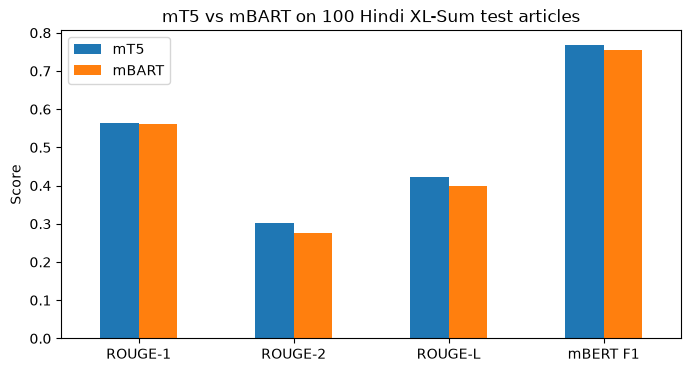

In [13]:
metrics = ['ROUGE-1', 'ROUGE-2', 'ROUGE-L', 'mBERT F1']
comparison.loc[metrics].plot(kind='bar', figsize=(8, 4), rot=0)
plt.title(f'mT5 vs mBART on {num_samples} Hindi XL-Sum test articles')
plt.ylabel('Score')
plt.show()

In [14]:
results_df = pd.DataFrame({
    'reference': reference_summaries,
    'mt5': mt5_summaries,
    'mbart': mbart_summaries,
    'mt5_rougeL': [scorer.score(r, p)['rougeL'].fmeasure for r, p in zip(reference_summaries, mt5_summaries)],
    'mbart_rougeL': [scorer.score(r, p)['rougeL'].fmeasure for r, p in zip(reference_summaries, mbart_summaries)],
})

print('Articles where mT5 is better (ROUGE-L):', (results_df['mt5_rougeL'] > results_df['mbart_rougeL']).sum())
print('Articles where mBART is better (ROUGE-L):', (results_df['mbart_rougeL'] > results_df['mt5_rougeL']).sum())
print()

best_gap = (results_df['mbart_rougeL'] - results_df['mt5_rougeL']).abs().idxmax()
print('Biggest difference example')
print('Reference:', results_df['reference'][best_gap])
print('mT5      :', results_df['mt5'][best_gap], round(results_df['mt5_rougeL'][best_gap], 3))
print('mBART    :', results_df['mbart'][best_gap], round(results_df['mbart_rougeL'][best_gap], 3))

Articles where mT5 is better (ROUGE-L): 59
Articles where mBART is better (ROUGE-L): 39

Biggest difference example
Reference: भारत की व्यावसायिक राजधानी मानेजाने वाली मुंबई में एक इमारत के ढह जाने से चार लोगों की मौत हो गई.
mT5      : भारत की राजधानी मुंबई में एक इमारत गिरने से चार लोगों की मौत हो गई है. 0.71
mBART    : मुंबई में मॉनसून के दौरान एक इमारत गिरने से कम से कम चार लोगों के शव बरामद किए गए हैं. 0.382


### Observations

- Both models are close on ROUGE-1 (0.563 vs 0.562), but mT5 is ahead on ROUGE-2, ROUGE-L and the mBERT score, so its summaries match the reference wording and order a bit better.
- mT5 writes shorter summaries (about 19 words vs 24 for mBART). The references are about 27 words long.
- mT5 has the better ROUGE-L on 59 of the 100 articles and mBART on 39.
- Both models sometimes add facts that are not in the article (for example "40 prisoners killed" in the Kandahar jail story), which ROUGE does not catch. This is a known problem with abstractive summarization.
- mBART was faster on my laptop (4.0s vs 6.2s per article), even though it has slightly more parameters.